In [1]:
import pandas as pd

ventas = pd.read_csv("../data/monthly_sales.csv")

ventas.head()

,stock_code,month,units
0,10002,2010-12-01,251
1,10002,2011-01-01,340
2,10002,2011-02-01,52
3,10002,2011-03-01,28
4,10002,2011-04-01,189


In [2]:
print(ventas.shape)

ventas.info()

(31108, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31108 entries, 0 to 31107
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   stock_code  31108 non-null  object
 1   month       31108 non-null  object
 2   units       31108 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 729.2+ KB


In [3]:
ventas["month"] = pd.to_datetime(ventas["month"])

ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31108 entries, 0 to 31107
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   stock_code  31108 non-null  object        
 1   month       31108 non-null  datetime64[ns]
 2   units       31108 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 729.2+ KB


In [4]:
print("Meses distintos en los datos:", ventas["month"].nunique())

print("Productos distintos:", ventas["stock_code"].nunique())

meses_por_producto = ventas.groupby("stock_code")["month"].count()

meses_por_producto.describe()

Meses distintos en los datos: 12
Productos distintos: 3803


,month
count,3803.000000
mean,8.179858
std,3.864314
min,1.000000
25%,5.000000
50%,9.000000
75%,12.000000
max,12.000000


In [5]:
tabla = ventas.pivot_table(index="stock_code",
                           columns="month",
                           values="units",
                           aggfunc="sum",
                           fill_value=0)

print(tabla.shape)

tabla.head()

(3803, 12)


month,2010-12-01,2011-01-01,2011-02-01,2011-03-01,2011-04-01,2011-05-01,2011-06-01,2011-07-01,2011-08-01,2011-09-01,2011-10-01,2011-11-01
stock_code,,,,,,,,,,,,
10002,251,340,52,28,189,0,0,0,0,0,0,0
10080,0,0,2,0,0,0,60,24,60,60,6,91
10120,16,0,30,29,0,3,0,5,35,10,10,49
10123C,1,0,0,4,0,0,0,0,0,0,0,0
10124A,4,0,3,5,0,0,0,0,0,0,0,4


In [6]:
resumen = pd.DataFrame()

resumen["demanda_media"] = tabla.mean(axis=1)

resumen["desviacion"] = tabla.std(axis=1, ddof=0)

resumen.head()

,demanda_media,desviacion
stock_code,,
10002,71.666667,114.082085
10080,25.250000,31.683658
10120,15.583333,15.660238
10123C,0.416667,1.114924
10124A,1.333333,1.929306


In [7]:
import numpy as np

lead_time = 1      # meses que tarda el proveedor (supuesto)
z = 1.65           # nivel de servicio del 95 %

resumen["stock_seguridad"] = np.ceil(z * resumen["desviacion"] * np.sqrt(lead_time))

resumen["punto_pedido"] = np.ceil(resumen["demanda_media"] * lead_time + resumen["stock_seguridad"])

resumen.head()

,demanda_media,desviacion,stock_seguridad,punto_pedido
stock_code,,,,
10002,71.666667,114.082085,189.0,261.0
10080,25.250000,31.683658,53.0,79.0
10120,15.583333,15.660238,26.0,42.0
10123C,0.416667,1.114924,2.0,3.0
10124A,1.333333,1.929306,4.0,6.0


In [8]:
productos = pd.read_csv("../data/products_clean.csv")

productos = productos.sort_values("revenue", ascending=False)

productos["pct_acumulado"] = productos["revenue"].cumsum() / productos["revenue"].sum()

productos.head()

,stock_code,description,revenue,units,pct_acumulado
1308,22423,REGENCY CAKESTAND 3 TIER,164762.19,13022,0.016894
3323,85123A,WHITE HANGING HEART T-LIGHT HOLDER,99846.98,35374,0.027132
2663,47566,PARTY BUNTING,98302.98,18018,0.037211
3307,85099B,JUMBO BAG RED RETROSPOT,92356.03,47359,0.046681
1940,23084,RABBIT NIGHT LIGHT,66756.59,30680,0.053526


In [9]:
def clase_abc(pct):
    if pct <= 0.80:
        return "A"
    elif pct <= 0.95:
        return "B"
    else:
        return "C"

productos["clase_abc"] = productos["pct_acumulado"].apply(clase_abc)

productos["clase_abc"].value_counts()

,count
clase_abc,
C,2008
B,963
A,834


In [10]:
resumen = resumen.reset_index()

resumen = resumen.merge(productos[["stock_code", "description", "clase_abc"]],
                        on="stock_code",
                        how="left")

print(resumen.shape)
print("Productos sin clase:", resumen["clase_abc"].isna().sum())

resumen.head()

(3803, 7)
Productos sin clase: 0


,stock_code,demanda_media,desviacion,stock_seguridad,punto_pedido,description,clase_abc
0,10002,71.666667,114.082085,189.0,261.0,INFLATABLE POLITICAL GLOBE,C
1,10080,25.250000,31.683658,53.0,79.0,GROOVY CACTUS INFLATABLE,C
2,10120,15.583333,15.660238,26.0,42.0,DOGGY RUBBER,C
3,10123C,0.416667,1.114924,2.0,3.0,HEARTS WRAPPING TAPE,C
4,10124A,1.333333,1.929306,4.0,6.0,SPOTS ON RED BOOKCOVER TAPE,C


In [11]:
z_por_clase = {"A": 2.05, "B": 1.65, "C": 1.28}

resumen["z"] = resumen["clase_abc"].map(z_por_clase)

resumen["stock_seguridad"] = np.ceil(resumen["z"] * resumen["desviacion"] * np.sqrt(lead_time))

resumen["punto_pedido"] = np.ceil(resumen["demanda_media"] * lead_time + resumen["stock_seguridad"])

resumen.groupby("clase_abc")[["stock_seguridad", "punto_pedido"]].sum()

,stock_seguridad,punto_pedido
clase_abc,,
A,434169.0,720362.0
B,164757.0,262282.0
C,67705.0,108717.0


In [12]:
sin_demanda = resumen[resumen["demanda_media"] <= 0]

print("Productos sin demanda real:", len(sin_demanda))

resumen = resumen[resumen["demanda_media"] > 0]

print("Productos que quedan:", len(resumen))

sin_demanda[["stock_code", "description", "demanda_media"]].head()

Productos sin demanda real: 26
Productos que quedan: 3777


,stock_code,description,demanda_media
157,20703,BLUE PADDED SOFT MOBILE,-0.500000
275,20957,PORCELAIN HANGING BELL SMALL,-0.083333
387,21144,PINK POODLE HANGING DECORATION,-0.583333
567,21412,VINTAGE GOLD TINSEL REEL,-0.500000
704,21645,ASSORTED TUTTI FRUTTI ROUND BOX,-2.000000


In [13]:
resumen = resumen.merge(productos[["stock_code", "revenue", "units"]],
                        on="stock_code",
                        how="left")

resumen["precio_medio"] = resumen["revenue"] / resumen["units"]

resumen["valor_stock_seguridad"] = resumen["stock_seguridad"] * resumen["precio_medio"]

resumen.groupby("clase_abc")["valor_stock_seguridad"].sum().round(0)

,valor_stock_seguridad
clase_abc,
A,1009985.0
B,214482.0
C,69888.0


In [14]:
resumen["stock_seguridad_95"] = np.ceil(1.65 * resumen["desviacion"] * np.sqrt(lead_time))

resumen["valor_95"] = resumen["stock_seguridad_95"] * resumen["precio_medio"]

comparacion = resumen.groupby("clase_abc")[["valor_95", "valor_stock_seguridad"]].sum().round(0)

comparacion["diferencia"] = comparacion["valor_stock_seguridad"] - comparacion["valor_95"]

comparacion

,valor_95,valor_stock_seguridad,diferencia
clase_abc,,,
A,813537.0,1009985.0,196448.0
B,214482.0,214482.0,0.0
C,89286.0,69888.0,-19398.0


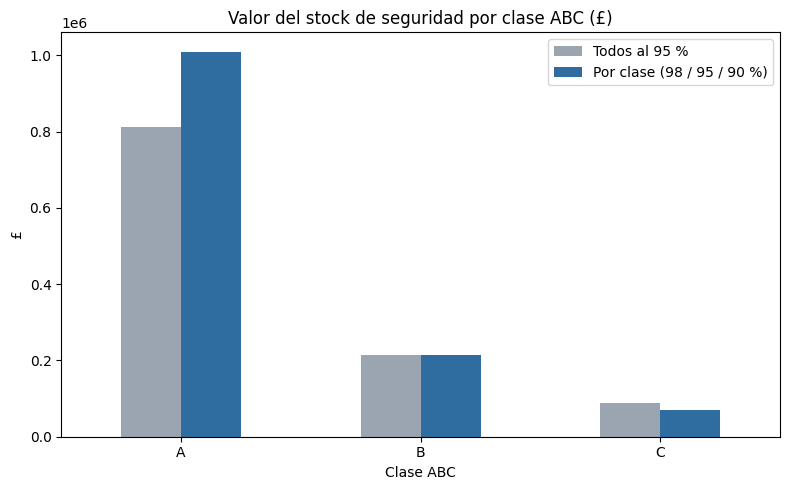

In [15]:
import matplotlib.pyplot as plt

comparacion[["valor_95", "valor_stock_seguridad"]].plot(kind="bar",
                                                       figsize=(8, 5),
                                                       color=["#9aa5b1", "#2f6c9f"])

plt.title("Valor del stock de seguridad por clase ABC (£)")
plt.xlabel("Clase ABC")
plt.ylabel("£")
plt.legend(["Todos al 95 %", "Por clase (98 / 95 / 90 %)"])
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("stock_seguridad_por_clase.png", dpi=150)
plt.show()

In [16]:
resultado = resumen[["stock_code", "description", "clase_abc",
                     "demanda_media", "desviacion", "z",
                     "stock_seguridad", "punto_pedido",
                     "precio_medio", "valor_stock_seguridad"]]

resultado = resultado.sort_values("valor_stock_seguridad", ascending=False)

resultado.to_csv("safety_stock_results.csv", index=False)

from google.colab import files
files.download("safety_stock_results.csv")
files.download("stock_seguridad_por_clase.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>